# 1 · The Italian thresholds in thirty seconds

How much rain does it take to trigger shallow landslides in Italy? This notebook reads the four T5 thresholds shipped with the library, turns them into millimetres, and draws them over the 5,974 landslides of e-ITALICA they were fitted on.

No network: the catalogue is in `tests/fixtures/`.

> **A threshold exceeded is not an alert.** It says the rain is like the rain that triggered landslides before. The official alert in Italy is the criticality bulletin of the Dipartimento della Protezione Civile.

In [1]:
import matplotlib.pyplot as plt

from rainfall_thresholds import ITALICA_T5, MACROREGIONS, macroregion_of

## The four thresholds

Each is a line `I = α · D^(-β)`: mean intensity `I` in mm/h, duration `D` in hours. `cumulated(D)` gives the total rain the line asks for.

In [2]:
print(f"{'':>9} {'alpha':>6} {'beta':>6}   rain needed in   6 h   24 h   72 h")
for name, t in ITALICA_T5.items():
    mm = [t.cumulated(d) for d in (6, 24, 72)]
    print(
        f"{name:>9} {t.alpha:6.3f} {t.beta:6.4f}   {'':>14} {mm[0]:4.1f} {mm[1]:6.1f} {mm[2]:6.1f}"
    )

           alpha   beta   rain needed in   6 h   24 h   72 h
    italy  7.193 0.5685                  15.6   28.3   45.5
 northern  6.400 0.5134                  15.3   30.0   51.3
  central  7.953 0.6085                  16.0   27.6   42.4
 southern  8.754 0.6449                  16.5   27.1   40.0


For short bursts the regions behave alike. Over days, the north asks for more rain than the south before landslides start.

## Which threshold for which region

Abruzzo and Molise are in the **centre**, as in e-ITALICA, not in the ISTAT south.

In [3]:
for region in ("Liguria", "Abruzzo", "Molise", "Calabria", "Bavaria"):
    print(f"{region:<10} -> {macroregion_of(region)}")

Liguria    -> northern
Abruzzo    -> central
Molise     -> central
Calabria   -> southern
Bavaria    -> None


## The landslides behind the lines

In [4]:
import csv
from pathlib import Path

FIXTURE = Path("../tests/fixtures/italica_v4_dur_rain.csv")
with FIXTURE.open(encoding="utf-8") as f:
    italica = [
        (r["region"], float(r["duration_h"]), float(r["cumulated_rainfall_mm"]))
        for r in csv.DictReader(f)
    ]
len(italica)

5974

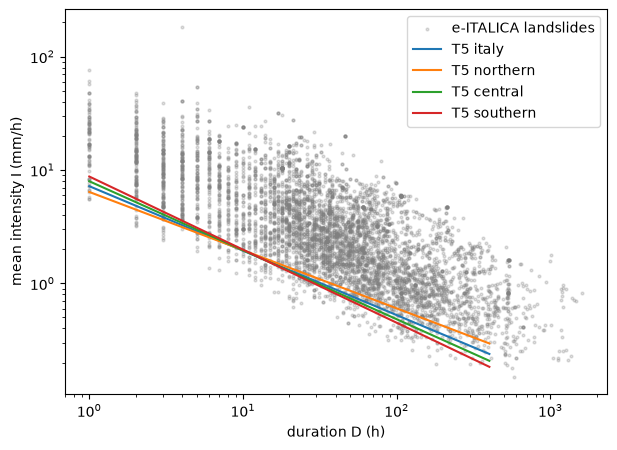

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))
d = [x[1] for x in italica]
i = [x[2] / x[1] for x in italica]
ax.scatter(d, i, s=4, alpha=0.25, color="grey", label="e-ITALICA landslides")
durations = [1 + k * 0.5 for k in range(0, 2 * 400)]
for name, t in ITALICA_T5.items():
    ax.plot(durations, [t.intensity(x) for x in durations], label=f"T5 {name}")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("duration D (h)")
ax.set_ylabel("mean intensity I (mm/h)")
ax.legend()
plt.show()

## How many landslides sit under each line

T5 is fitted so that about 5 % of the landslides of its area sit under it. Counted on the catalogue itself:

In [6]:
for name, t in ITALICA_T5.items():
    regions = MACROREGIONS.get(name)
    rows = [x for x in italica if regions is None or x[0] in regions]
    below = sum(t.exceedance(e / d, d) < 0 for _, d, e in rows)
    print(f"{name:>9}: {below:4d} of {len(rows):4d} below = {100 * below / len(rows):.1f} %")

    italy:  299 of 5974 below = 5.0 %
 northern:  133 of 2659 below = 5.0 %
  central:   95 of 1890 below = 5.0 %
 southern:   72 of 1425 below = 5.1 %


Those are real landslides that a T5 threshold does not catch. The other side, how often T5 is exceeded on days without landslides, is not in this catalogue: it is measured in [#7](https://github.com/agent-engineering-studio/rainfall-thresholds/issues/7).